In [1]:
import sys
sys.path.append("..")
 
import numpy as np
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from src.utils import get_distilbert_tokenizer, compress_random, compress_perplexity
from src.scorer import load_scorer, TokenScorer
 
scorer = load_scorer("../models/scorer.pt")
tok    = get_distilbert_tokenizer()
squad = load_dataset("rajpurkar/squad", split="validation")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

In [2]:
model = TokenScorer(freeze_encoder=True)
model.load_state_dict(torch.load("../models/scorer.pt", map_location="cpu"))
model.eval()

def compress_learned(text: str, ratio: float) -> dict:
    enc = tok(text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        scores = model(enc.input_ids, enc.attention_mask).squeeze()
    tokens = tok.convert_ids_to_tokens(enc.input_ids.squeeze())
    k = max(1, int(len(tokens) * ratio))
    top_idx = sorted(torch.topk(scores, k).indices.tolist())
    kept_tokens = [tokens[i] for i in top_idx]
    compressed = tok.convert_tokens_to_string(kept_tokens)
    return {
        "compressed": compressed,
        "original_tokens": len(tokens),
        "kept_tokens": k,
        "ratio_actual": k / len(tokens),
        "scores": scores.tolist(),
        "tokens": tokens
    }

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [3]:
from evaluate import load
rouge = load("rouge")

results = []


In [4]:
for row in squad.select(range(100)):
    ctx = row["context"]
    for method, fn in [("random", compress_random),
                       ("perplexity", compress_perplexity),
                       ("learned", lambda t, r: compress_learned(t, r)["compressed"])]:
        for ratio in [0.3, 0.5, 0.7]:
            compressed = fn(ctx, ratio)
            score = rouge.compute(predictions=[compressed], references=[ctx])
            results.append({"method": method, "ratio": ratio,
                             "rouge1": score["rouge1"], "rouge2": score["rouge2"]})

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

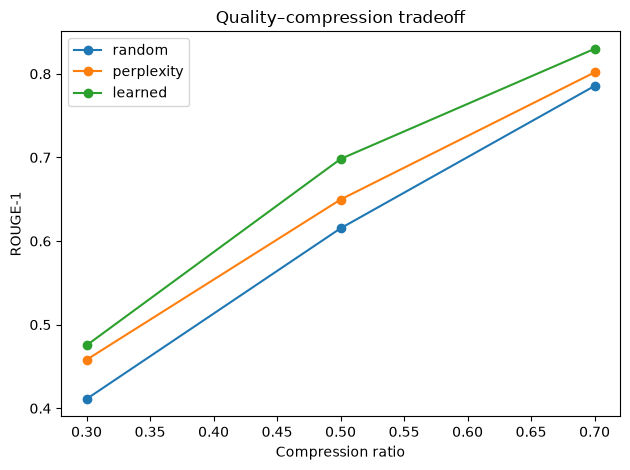

In [5]:
import pandas as pd
df = pd.DataFrame(results)
for method in ["random", "perplexity", "learned"]:
    sub = df[df.method == method].groupby("ratio")["rouge1"].mean()
    plt.plot(sub.index, sub.values, marker="o", label=method)
plt.xlabel("Compression ratio"); plt.ylabel("ROUGE-1")
plt.legend(); plt.title("Quality–compression tradeoff"); plt.tight_layout()


In [6]:
plt.savefig("../results/tradeoff_curve.png", dpi=150); plt.show()

<Figure size 640x480 with 0 Axes>